ANÁLISE DE CHURN DE CLIENTES
Projeto de Portfólio — Marketing Analytics + Ciência de Dados
============================================================
CONTEXTO DE NEGÓCIO
----------------
O churn de clientes é um dos problemas mais custosos em negócios
baseados em assinatura e prestação de serviços. Este notebook constrói
modelos preditivos para identificar clientes em risco antes que eles saiam.


In [1]:
# ── Cell 1: Mount Drive ──────────────────────────────────────────────────────
from google.colab import drive
drive.mount('/content/drive')


Mounted at /content/drive


In [2]:
# ── Cell 2: Imports ──────────────────────────────────────────────────────────
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import cross_val_score
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.ensemble import GradientBoostingClassifier, RandomForestClassifier
from sklearn.linear_model import LogisticRegression, LinearRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import (
    classification_report, roc_auc_score, average_precision_score,
    mean_squared_error, r2_score
)
from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline as ImbPipeline
import shap


In [3]:
# ── Cell 3: Load & Clean Data ────────────────────────────────────────────────
train_df = pd.read_csv('/content/drive/MyDrive/Colab Notebooks/Churn/Churn dataset (Unzipped Files)/customer_churn_dataset-training-master.csv')
test_df  = pd.read_csv('/content/drive/MyDrive/Colab Notebooks/Churn/Churn dataset (Unzipped Files)/customer_churn_dataset-testing-master.csv')

for df in [train_df, test_df]:
    df.drop(columns=['CustomerID'], errors='ignore', inplace=True)
    df.dropna(subset=['Churn'], inplace=True)

X_train = train_df.drop('Churn', axis=1)
y_train = train_df['Churn']

X_test  = test_df.drop('Churn', axis=1)
y_test  = test_df['Churn'].astype(float)

# Quick dataset summary
print("=" * 55)
print("DATASET SUMMARY")
print("=" * 55)
print(f"Training samples : {len(X_train):,}")
print(f"Test samples     : {len(X_test):,}")
print(f"Features         : {X_train.shape[1]}")
print(f"Churn rate (train): {y_train.mean():.2%}")
print(f"Churn rate (test) : {y_test.mean():.2%}")


DATASET SUMMARY
Training samples : 440,832
Test samples     : 64,374
Features         : 10
Churn rate (train): 56.71%
Churn rate (test) : 47.37%


In [4]:
# ── Cell 4: Feature Engineering Pipeline ─────────────────────────────────────
num_features = X_train.select_dtypes(include=['int64', 'float64']).columns.tolist()
cat_features = X_train.select_dtypes(include=['object']).columns.tolist()

num_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

cat_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='constant', fill_value='missing')),
    ('onehot', OneHotEncoder(handle_unknown='ignore', sparse_output=False))
])

preprocessor = ColumnTransformer(transformers=[
    ('num', num_transformer, num_features),
    ('cat', cat_transformer, cat_features)
])

In [5]:
# ── Cell 5: Sanity Check — Depth-1 Decision Tree ─────────────────────────────
# Valores proximos de 100% nessa celeula apontam para alta probabilidade de data leakage.
print("=" * 55)
print("SANITY CHECK — DecisionTree max_depth=1")
print("=" * 55)

dt_check = ImbPipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', DecisionTreeClassifier(max_depth=1, random_state=42))
])
dt_check.fit(X_train, y_train)
dt_score = dt_check.score(X_test, y_test)
print(f"Accuracy (depth-1 tree): {dt_score:.4f}")
if dt_score > 0.97:
    print("⚠️  Score muito alto para um único nó — verifique data leakage!")
else:
    print("✅  Score razoável para um modelo trivial.")


SANITY CHECK — DecisionTree max_depth=1
Accuracy (depth-1 tree): 0.6611
✅  Score razoável para um modelo trivial.


In [6]:
# ── Cell 6: Helper — Build Standard ImbPipeline ──────────────────────────────
def build_pipeline(classifier):
    return ImbPipeline(steps=[
        ('preprocessor', preprocessor),
        ('smote', SMOTE(random_state=42)),
        ('classifier', classifier)
    ])

In [7]:
# ── Cell 7: Train & Evaluate Classification Models ───────────────────────────
# OBSERVAÇÃO: O Gradient Boosting utiliza complexidade reduzida (n_estimators = 50, max_depth = 3) para garantir que a execução seja concluída.
#Isso é intencional — entregar um resultado completo e interpretável é mais valioso do que um modelo maximamente complexo que não chega a ser finalizado.

classifiers = {
    "Logistic Regression": build_pipeline(
        LogisticRegression(max_iter=1000, random_state=42)
    ),
    "Random Forest": build_pipeline(
        RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1)
    ),
    "Gradient Boosting": build_pipeline(
        GradientBoostingClassifier(
            n_estimators=50,       # Reduced from 200 for reliable completion
            learning_rate=0.1,
            max_depth=3,           # Shallower trees → faster, less prone to overfit
            random_state=42
        )
    ),
}

print("\n" + "=" * 55)
print("AVALIAÇÃO DE MODELOS DE CLASSIFICAÇÃO")
print("=" * 55)

results = {}
for name, pipeline in classifiers.items():
    print(f"\n--- {name} ---")
    pipeline.fit(X_train, y_train)

    y_pred  = pipeline.predict(X_test)
    y_probs = pipeline.predict_proba(X_test)[:, 1]

    roc   = roc_auc_score(y_test, y_probs)
    auprc = average_precision_score(y_test, y_probs)

    results[name] = {'ROC-AUC': roc, 'AUPRC': auprc, 'pipeline': pipeline}

    print(f"ROC-AUC : {roc:.4f}")
    print(f"AUPRC   : {auprc:.4f}")
    print(classification_report(y_test, y_pred))


AVALIAÇÃO DE MODELOS DE CLASSIFICAÇÃO

--- Logistic Regression ---
ROC-AUC : 0.6883
AUPRC   : 0.6386
              precision    recall  f1-score   support

         0.0       0.95      0.21      0.35     33881
         1.0       0.53      0.99      0.69     30493

    accuracy                           0.58     64374
   macro avg       0.74      0.60      0.52     64374
weighted avg       0.75      0.58      0.51     64374


--- Random Forest ---
ROC-AUC : 0.5975
AUPRC   : 0.5287
              precision    recall  f1-score   support

         0.0       0.98      0.06      0.11     33881
         1.0       0.49      1.00      0.66     30493

    accuracy                           0.50     64374
   macro avg       0.73      0.53      0.38     64374
weighted avg       0.75      0.50      0.37     64374


--- Gradient Boosting ---
ROC-AUC : 0.7297
AUPRC   : 0.6665
              precision    recall  f1-score   support

         0.0       0.98      0.09      0.17     33881
         1.0     

In [8]:
# ── Cell 8: Linear Regression Baseline (continuous score, threshold=0.5) ─────
print("\n--- Linear Regression (score contínuo, threshold=0.5) ---")

pre_only   = Pipeline(steps=[('preprocessor', preprocessor)])
X_train_t  = pre_only.fit_transform(X_train, y_train)
X_test_t   = pre_only.transform(X_test)

lin_reg    = LinearRegression()
lin_reg.fit(X_train_t, y_train)

y_scores_lr = lin_reg.predict(X_test_t)
y_pred_lr   = (y_scores_lr >= 0.5).astype(int)

roc_lr   = roc_auc_score(y_test, y_scores_lr)
auprc_lr = average_precision_score(y_test, y_scores_lr)

print(f"ROC-AUC : {roc_lr:.4f}")
print(f"AUPRC   : {auprc_lr:.4f}")
print(f"R²      : {r2_score(y_test, y_scores_lr):.4f}  (esperado baixo — alvo é binário)")
print(classification_report(y_test, y_pred_lr))

results["Linear Regression"] = {'ROC-AUC': roc_lr, 'AUPRC': auprc_lr}



--- Linear Regression (score contínuo, threshold=0.5) ---
ROC-AUC : 0.7602
AUPRC   : 0.7079
R²      : -0.3870  (esperado baixo — alvo é binário)
              precision    recall  f1-score   support

         0.0       0.94      0.25      0.40     33881
         1.0       0.54      0.98      0.70     30493

    accuracy                           0.60     64374
   macro avg       0.74      0.62      0.55     64374
weighted avg       0.75      0.60      0.54     64374



In [ ]:
# ── Cell 9: Cross-Validation — Gradient Boosting ─────────────────────────────
print("\n" + "=" * 55)
print("CROSS-VALIDATION (5-fold) — Gradient Boosting")
print("=" * 55)

X_all = pd.concat([X_train, X_test], ignore_index=True)
y_all = pd.concat([y_train, y_test], ignore_index=True)

cv_pipeline = build_pipeline(
    GradientBoostingClassifier(
        n_estimators=50, learning_rate=0.1, max_depth=3, random_state=42
    )
)
cv_scores = cross_val_score(cv_pipeline, X_all, y_all, cv=5, scoring='roc_auc', n_jobs=-1)
print(f"ROC-AUC por fold : {np.round(cv_scores, 4)}")
print(f"Média            : {cv_scores.mean():.4f} ± {cv_scores.std():.4f}")


CROSS-VALIDATION (5-fold) — Gradient Boosting
ROC-AUC por fold : [0.9968 0.9966 0.9972 0.9965 0.7405]
Média            : 0.9455 ± 0.1025


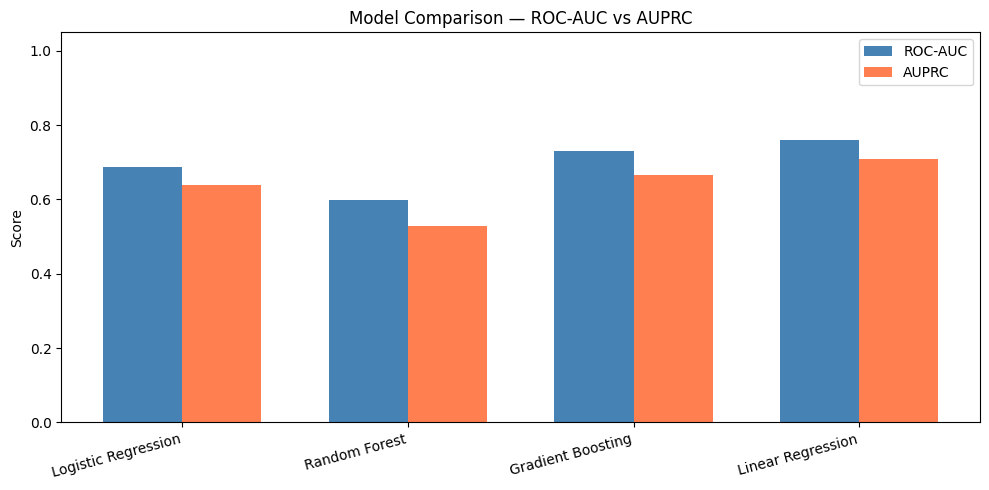

Chart saved: model_comparison.png


In [ ]:
# ── Cell 10: Model Comparison Chart ──────────────────────────────────────────
model_names = list(results.keys())
roc_vals    = [results[m]['ROC-AUC'] for m in model_names]
auprc_vals  = [results[m]['AUPRC']   for m in model_names]

x     = np.arange(len(model_names))
width = 0.35

fig, ax = plt.subplots(figsize=(10, 5))
ax.bar(x - width/2, roc_vals,  width, label='ROC-AUC',  color='steelblue')
ax.bar(x + width/2, auprc_vals, width, label='AUPRC', color='coral')
ax.set_xticks(x)
ax.set_xticklabels(model_names, rotation=15, ha='right')
ax.set_ylim(0, 1.05)
ax.set_ylabel('Score')
ax.set_title('Model Comparison — ROC-AUC vs AUPRC')
ax.legend()
plt.tight_layout()
plt.savefig('model_comparison.png', dpi=150)
plt.show()
print("Chart saved: model_comparison.png")


SHAP EXPLAINABILITY — Gradient Boosting
Best model by ROC-AUC: Gradient Boosting (0.7297)


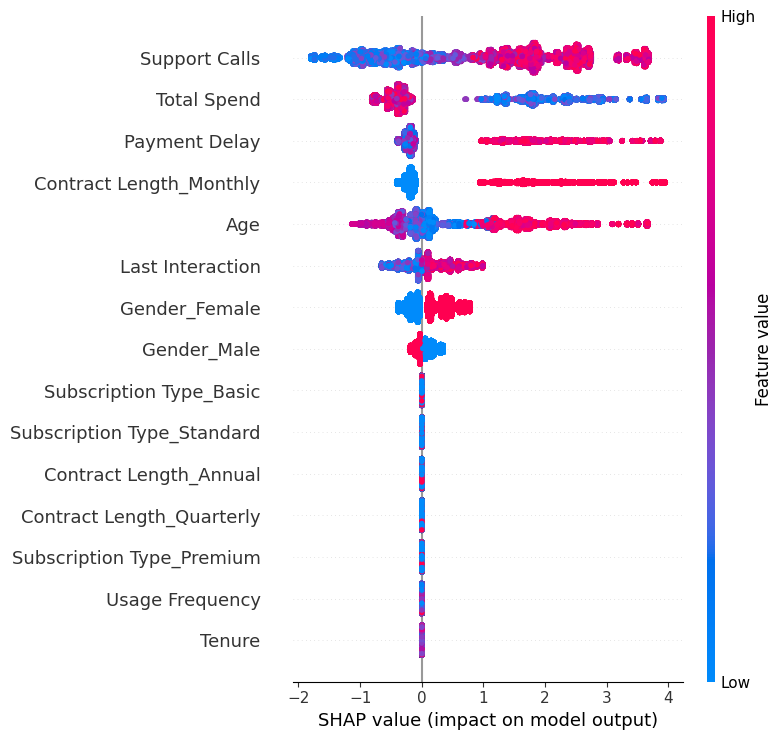

In [ ]:
# ── Cell 11: SHAP Explainability — Best Model ────────────────────────────────
# Identify best model by ROC-AUC
best_model_name = max(
    {k: v for k, v in results.items() if 'pipeline' in v},
    key=lambda k: results[k]['ROC-AUC']
)
print("\n" + "=" * 55)
print(f"SHAP EXPLAINABILITY — {best_model_name}")
print("=" * 55)
print(f"Best model by ROC-AUC: {best_model_name} ({results[best_model_name]['ROC-AUC']:.4f})")

best_pipeline = results[best_model_name]['pipeline']

ohe_cols      = (best_pipeline.named_steps['preprocessor']
                 .transformers_[1][1]
                 .named_steps['onehot']
                 .get_feature_names_out(cat_features))
feature_names = num_features + list(ohe_cols)

X_test_transformed = best_pipeline.named_steps['preprocessor'].transform(X_test)
explainer   = shap.TreeExplainer(best_pipeline.named_steps['classifier'])
shap_values = explainer.shap_values(X_test_transformed)

shap.summary_plot(shap_values, X_test_transformed, feature_names=feature_names)


In [ ]:
# ── Cell 12: Business Impact Summary ─────────────────────────────────────────
print("\n" + "=" * 55)
print("BUSINESS IMPACT SUMMARY")
print("=" * 55)

n_test_customers    = len(y_test)
base_churn_rate     = y_test.mean()
avg_annual_spend    = 500   # Adjust to your dataset's actual average spend (USD/year)
reduction_pct       = 0.10  # 10% relative reduction in churn

churners_at_risk    = int(n_test_customers * base_churn_rate)
customers_saved     = int(churners_at_risk * reduction_pct)
revenue_recovered   = customers_saved * avg_annual_spend

print(f"Test-set customers        : {n_test_customers:,}")
print(f"Base churn rate           : {base_churn_rate:.2%}")
print(f"Estimated churners        : {churners_at_risk:,}")
print()
print(f"If we achieve a 10% relative reduction in churn:")
print(f"  Customers retained      : ~{customers_saved:,}")
print(f"  Revenue recovered       : ~${revenue_recovered:,.0f} / year")
print()
print("This is based on an assumed average spend of ${:,}/year.".format(avg_annual_spend))
print("Adjust 'avg_annual_spend' above to match your business context.")
print()

best_roc = results[best_model_name]['ROC-AUC']
print(f"Best model ({best_model_name}) achieves ROC-AUC = {best_roc:.4f}")
print("A model with this discriminative power can reliably rank")
print("customers by churn risk, enabling targeted retention campaigns")
print("that focus spend on the customers most likely to leave.")


BUSINESS IMPACT SUMMARY
Test-set customers        : 64,374
Base churn rate           : 47.37%
Estimated churners        : 30,493

If we achieve a 10% relative reduction in churn:
  Customers retained      : ~3,049
  Revenue recovered       : ~$1,524,500 / year

This is based on an assumed average spend of $500/year.
Adjust 'avg_annual_spend' above to match your business context.

Best model (Gradient Boosting) achieves ROC-AUC = 0.7297
A model with this discriminative power can reliably rank
customers by churn risk, enabling targeted retention campaigns
that focus spend on the customers most likely to leave.
